# Mall Customers Clustering

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

## Load and Display Dataset

In [2]:
data = pd.read_csv("Mall_Customers.csv")

print("First five rows:")
print(data.head())

print("\nDataset information:")
data.info()

print("\nMissing values:")
print(data.isnull().sum())

First five rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Missing values:
CustomerID            

## Select Features

In [3]:
features = data[["Annual Income (k$)", "Spending Score (1-100)"]]
features = features.fillna(features.mean())

## K-Means Without Scaling

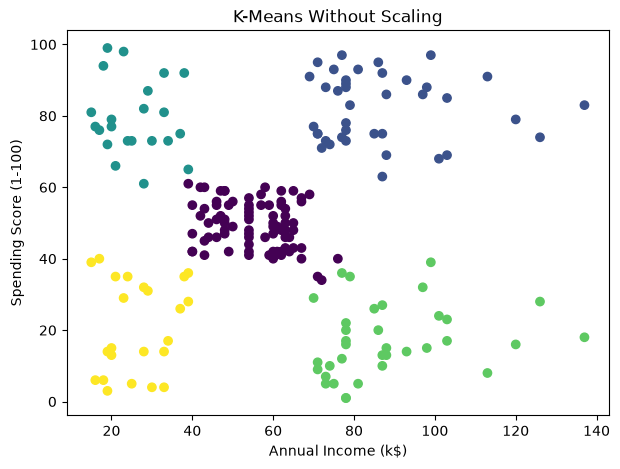

In [4]:
k = 5

kmeans_original = KMeans(
    n_clusters=k, random_state=42, n_init=10
)
labels_original = kmeans_original.fit_predict(features)

plt.figure(figsize=(7, 5))
plt.scatter(
    features["Annual Income (k$)"],
    features["Spending Score (1-100)"],
    c=labels_original, cmap="viridis"
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Without Scaling")
plt.show()

## Feature Scaling

In [5]:
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

## DBSCAN

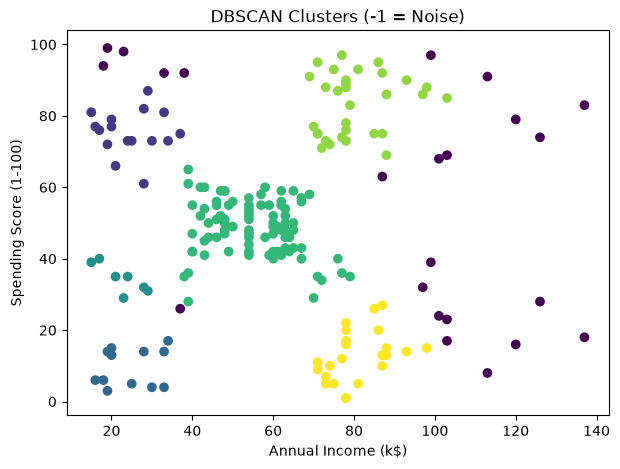


DBSCAN cluster counts:
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64


In [6]:
dbscan = DBSCAN(eps=0.35, min_samples=5)
labels_dbscan = dbscan.fit_predict(features_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(
    features["Annual Income (k$)"],
    features["Spending Score (1-100)"],
    c=labels_dbscan, cmap="viridis"
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN Clusters (-1 = Noise)")
plt.show()

print("\nDBSCAN cluster counts:")
print(pd.Series(labels_dbscan).value_counts().sort_index())

## K-Means After Scaling

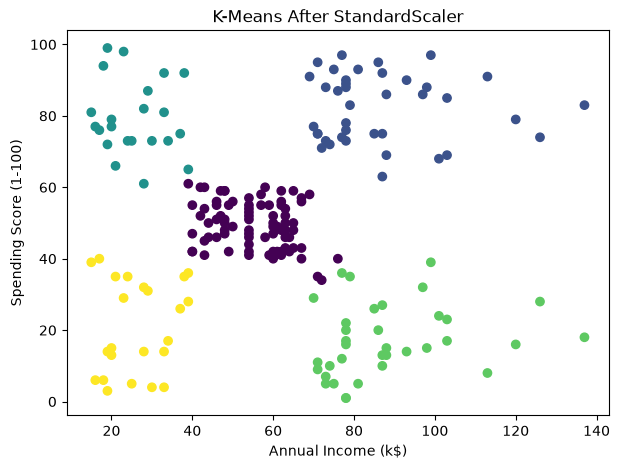

In [7]:
kmeans_scaled = KMeans(
    n_clusters=k, random_state=42, n_init=10
)
labels_scaled = kmeans_scaled.fit_predict(features_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(
    features["Annual Income (k$)"],
    features["Spending Score (1-100)"],
    c=labels_scaled, cmap="viridis"
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means After StandardScaler")
plt.show()

## Compare Before and After Scaling

In [8]:
ari = adjusted_rand_score(labels_original, labels_scaled)

print("\nAdjusted Rand Index:", round(ari, 3))

if ari == 1:
    print("Scaling did not change the cluster assignments.")
else:
    print("Scaling changed some cluster assignments.")


Adjusted Rand Index: 1.0
Scaling did not change the cluster assignments.


## Elbow Method

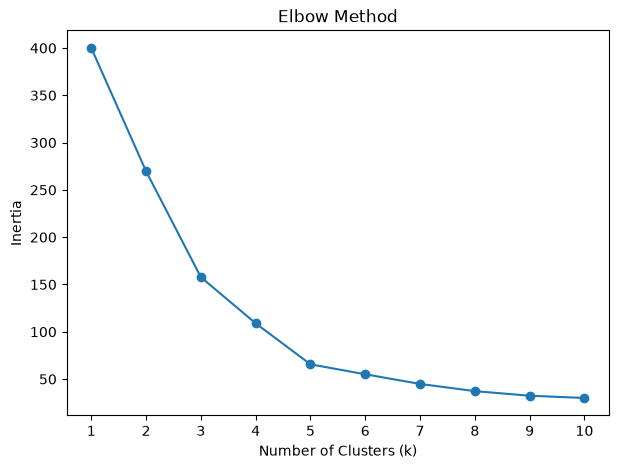

In [9]:
inertias = []

for i in range(1, 11):
    model = KMeans(
        n_clusters=i, random_state=42, n_init=10
    )
    model.fit(features_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

## Cluster Interpretation

In [10]:
summary = features.copy()
summary["Cluster"] = labels_scaled

print("\nCluster averages:")
print(summary.groupby("Cluster").mean().round(2))

income_median = features["Annual Income (k$)"].median()
spending_median = features["Spending Score (1-100)"].median()

print("\nCluster Interpretation:")

for cluster, row in summary.groupby("Cluster").mean().iterrows():
    income = row["Annual Income (k$)"]
    spending = row["Spending Score (1-100)"]

    if income >= income_median and spending >= spending_median:
        description = "High income, high spending"
    elif income >= income_median and spending < spending_median:
        description = "High income, low spending"
    elif income < income_median and spending >= spending_median:
        description = "Low income, high spending"
    else:
        description = "Low income, low spending"

    print("Cluster", cluster, ":", description)


Cluster averages:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91

Cluster Interpretation:
Cluster 0 : Low income, low spending
Cluster 1 : High income, high spending
Cluster 2 : Low income, high spending
Cluster 3 : High income, low spending
Cluster 4 : Low income, low spending


## Add LuckyNumber Feature

In [11]:
np.random.seed(42)
data["LuckyNumber"] = np.random.randint(0, 101, size=len(data))

print("\nDataset with LuckyNumber:")
print(data.head())

features_lucky = data[
    ["Annual Income (k$)", "Spending Score (1-100)", "LuckyNumber"]
].copy()

features_lucky = features_lucky.fillna(features_lucky.mean())

scaler_lucky = StandardScaler()
features_lucky_scaled = scaler_lucky.fit_transform(features_lucky)


Dataset with LuckyNumber:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   LuckyNumber  
0           51  
1           92  
2           14  
3           71  
4           60  


## K-Means With LuckyNumber


Comparison after adding LuckyNumber:
Adjusted Rand Index: 0.491


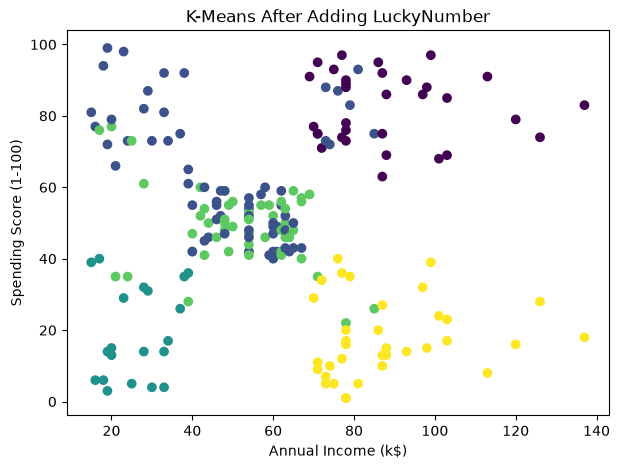

In [12]:
kmeans_lucky = KMeans(
    n_clusters=k, random_state=42, n_init=10
)
labels_lucky = kmeans_lucky.fit_predict(features_lucky_scaled)

ari_lucky = adjusted_rand_score(labels_scaled, labels_lucky)

print("\nComparison after adding LuckyNumber:")
print("Adjusted Rand Index:", round(ari_lucky, 3))

plt.figure(figsize=(7, 5))
plt.scatter(
    features["Annual Income (k$)"],
    features["Spending Score (1-100)"],
    c=labels_lucky, cmap="viridis"
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means After Adding LuckyNumber")
plt.show()

## Conclusion
Scaling changes the relative influence of features on distance.
The Elbow plot helps estimate the best value of k.
LuckyNumber is random and has no real customer meaning.
It can change clusters because K-Means uses distances between features.
Avoid irrelevant features when building meaningful customer segments.